# E-Commerce Customer Churn Prediction

## Project Overview

This project analyzes e-commerce customer behavior to identify patterns associated with customer churn and develop machine learning models that can help businesses identify customers at risk of leaving.

The analysis combines exploratory data analysis, data preprocessing, classification modeling, and performance evaluation to generate insights that can support customer retention strategies.

## Project Objectives

- Explore customer behavior and identify patterns associated with churn.
- Investigate missing values, feature relationships, and class imbalance.
- Develop and compare multiple classification models.
- Evaluate model performance using metrics that reflect the importance of identifying customers who churn.
- Translate model findings into actionable business recommendations.

---

In [1]:
  #Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
  #Data loading
file_path = "data/loblaws.xlsx"
df = pd.read_excel(file_path, sheet_name="E Comm")

In [3]:
# what does the df looks like !!!
print ( f" Dataset shape:{df.shape} " )
print(f" # of rows: {df.shape[0]: ,} ")
print(f" # of columns:{df.shape[1]} ")

display(df.head())
display(df.dtypes.rename("Data Type").to_frame())

 Dataset shape:(5630, 20) 
 # of rows:  5,630 
 # of columns:20 


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


,Data Type
CustomerID,int64
Churn,int64
Tenure,float64
PreferredLoginDevice,object
CityTier,int64
WarehouseToHome,float64
PreferredPaymentMode,object
Gender,object
HourSpendOnApp,float64
NumberOfDeviceRegistered,int64


##### _first table shows the initial 5 rows of the data, the second table shows the datatypes of each column._

___

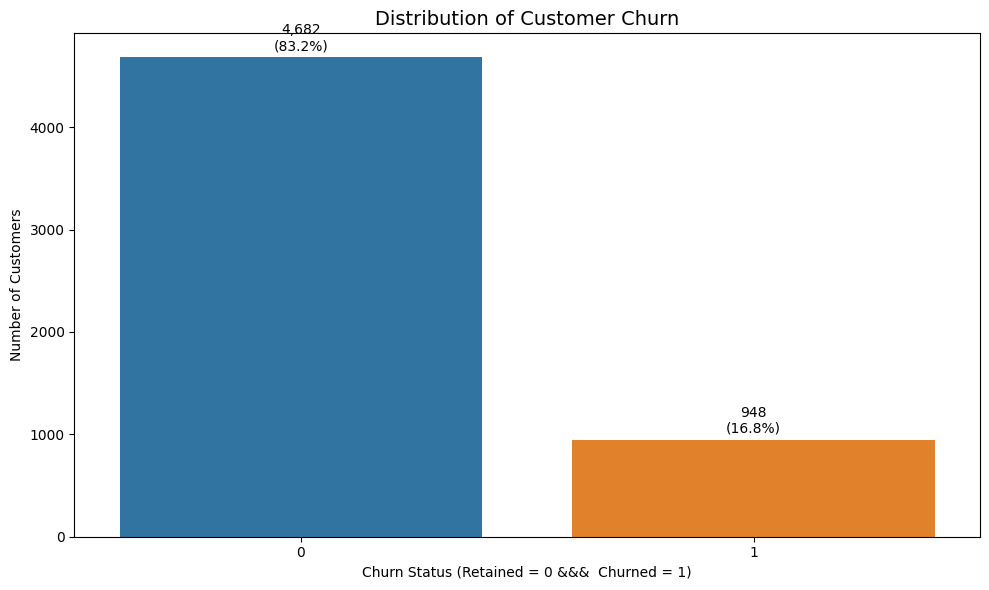

In [4]:
# Customer Churn Distribution

churn_counts = df["Churn"].value_counts().sort_index()

churn_percentages =(
    df["Churn"].value_counts(normalize=True).sort_index() * 100)

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df ,
    x="Churn",
    hue="Churn",
    order=churn_counts.index ,
    legend=False)

ax.set_title("Distribution of Customer Churn", fontsize=14)
ax.set_xlabel("Churn Status (Retained = 0 &&&  Churned = 1)")
ax.set_ylabel("Number of Customers")

for i, count in enumerate(churn_counts):
    ax.annotate(
        f"{count:,}\n({churn_percentages.loc[churn_counts.index[i]]:.1f}%)",
        (i, count),
        ha="center",
        xytext=(0, 5),
        textcoords="offset points"
    
    
    )

plt.tight_layout()
plt.show()

##### _Here, I am comparing showing the classes of customers in the dataset that I have. There are 2 clases, Class 0 and Class1. Class 0 is the class of the customers that are retained and class 1 are the churned customers. We have 948 churned customers, which is 16.8% of the total customers within the dataset_

---

In [5]:
from sklearn.model_selection import train_test_split

 #separate Features and Target
X = df.drop(columns=["Churn", "CustomerID"], errors="ignore")
y = df["Churn"]

# train + test split, test_size = 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 4,504
Testing samples: 1,126

Training churn distribution:
Churn
0    0.832
1    0.168
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    0.831
1    0.169
Name: proportion, dtype: float64


##### Train-Test Split Analysis

##### The dataset was divided into 80% training data and 20% testing data using stratified sampling to preserve the original churn distribution.

##### Approximately 83% of customers did not churn, while 17% churned. This distribution is consistent across both datasets.

##### Since the target variable is imbalanced, model performance will be evaluated using precision, recall, F1-score, and ROC-AUC in addition to accuracy.

---

In [6]:
# # Defining Preprocessing Pipelines

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 13
Categorical features: 5


##### Data Preprocessing

_Before training the machine learning models, we need to prepare the data. The dataset contains 13 numerical features and 5 categorical features, which require different preprocessing steps._

_For numerical features, missing values are replaced with the median, and __"StandardScaler"__ is used to put the values on a similar scale. For categorical features, missing values are replaced with the most common value, and __"OneHotEncoder"__ converts text categories into numbers._

_We use __"ColumnTransformer"__ and __"Pipeline"__ to organize these steps and apply them automatically during model training. This also helps prevent data leakage because the preprocessing rules are learned from the training data and then applied to the testing data._

---

In [7]:
# Model Training and Comparison, I have done Logistic Regression, Decision Tree & Random Forest

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state= 42),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1)
}

results = []
trained_models = {}

for name, classifier in models.items():

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model_pipeline.fit(X_train, y_train)

    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = model_pipeline

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.974,0.994,0.853,0.918,0.998
1,Decision Tree,0.960,0.880,0.884,0.882,0.930
2,Logistic Regression,0.791,0.438,0.842,0.577,0.886


### Model Training and Comparison

##### I have trained three machine learning models: 
1) Logistic Regression, 
2) Decision Tree,  
3) Random Forest 
to predict customer churn. 
##### I have used class_weight="balanced" to handle class imbalance and evaluated each model using 
1) Accuracy,
2) Precision,
3) Recall,
4) F1 Score, 
5) ROC-AUC.

### Model Comparison Results

##### The results show that **Random Forest performed the best overall**, achieving **97.4% accuracy, 99.4% precision, 85.3% recall, and a 91.8% F1 Score**. This means the model correctly predicts most customers and makes very few false churn predictions. The Decision Tree also performed well, achieving 96.0% accuracy and 88.2% F1 Score. Interestingly, the Decision Tree had a slightly higher recall (88.4%) than Random Forest (85.3%), meaning it identified a larger percentage of customers who actually churned.

##### Logistic Regression had the lowest overall performance, with 79.1% accuracy and a 57.7% F1 Score. Although it achieved a relatively high recall of 84.2%, its precision was only 43.8%, meaning many customers predicted to churn did not actually churn. **Based on the F1 Score, Random Forest is the best-performing model in this comparison**, as it provides the strongest balance between precision and recall. It also achieved the highest ROC-AUC score of 0.998, showing excellent ability to distinguish between customers who churn and those who stay.

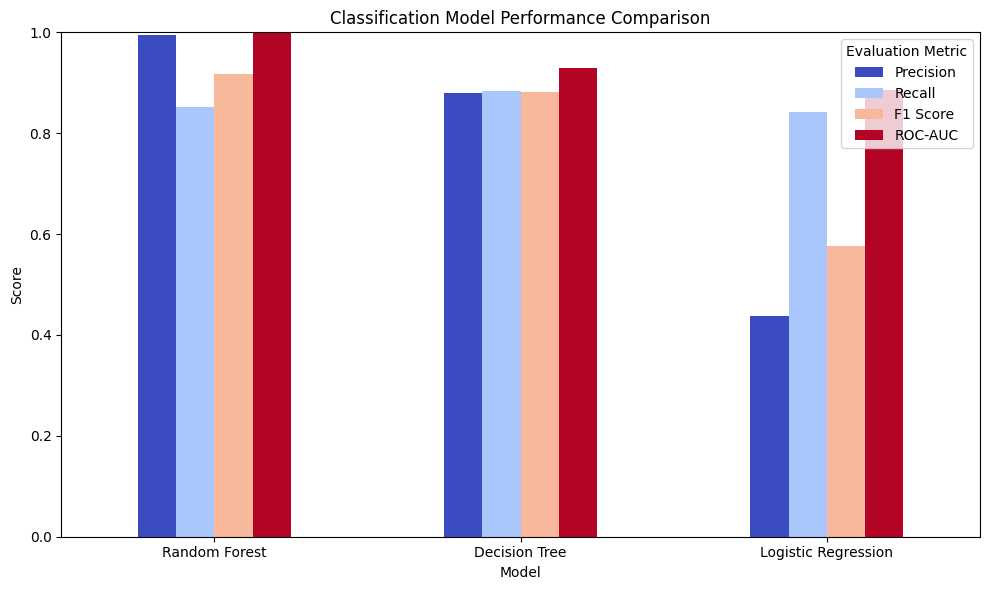

In [8]:
# Model Performance Comparison

metrics_to_plot = ["Precision", "Recall", "F1 Score", "ROC-AUC"]

plot_data = results_df.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    cmap = "coolwarm"
)

#Color Combination choices => 'viridis', 'plasma', 'magma',   => 'coolwarm' <=  , and 'Pastel1'


ax.set_title("Classification Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.legend(title="Evaluation Metric")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

##### Graphical visualization of model performance in the plot above

---

Selected model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       936
           1       0.99      0.85      0.92       190

    accuracy                           0.97      1126
   macro avg       0.98      0.93      0.95      1126
weighted avg       0.97      0.97      0.97      1126



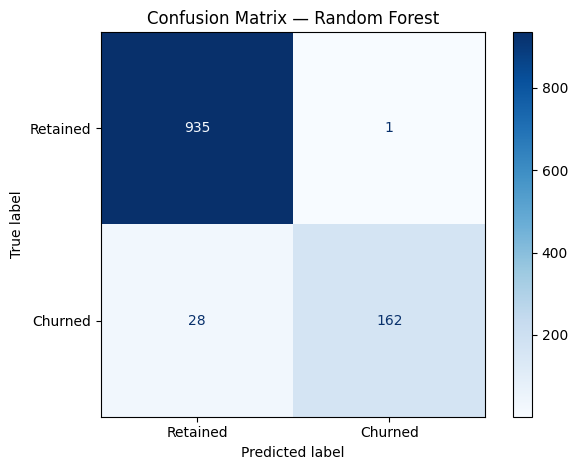

In [9]:
# Evaluating Random Forest  => "the Selected Model"

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Retained", "Churned"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

#####  Random Forest Model Evaluation

The __Random Forest model__ achieved __97.4% accuracy__ on the testing dataset. The confusion matrix shows that the model correctly predicted __935 retained customers and 162 churned customers__, while incorrectly predicting __1 retained customer as churned and 28 churned customers as retained__. The model achieved __99% precision and 85% recall__ for churned customers, meaning its churn predictions were highly accurate, but it missed some customers who actually churned. Overall, the results show that Random Forest performs well at predicting customer churn.

---

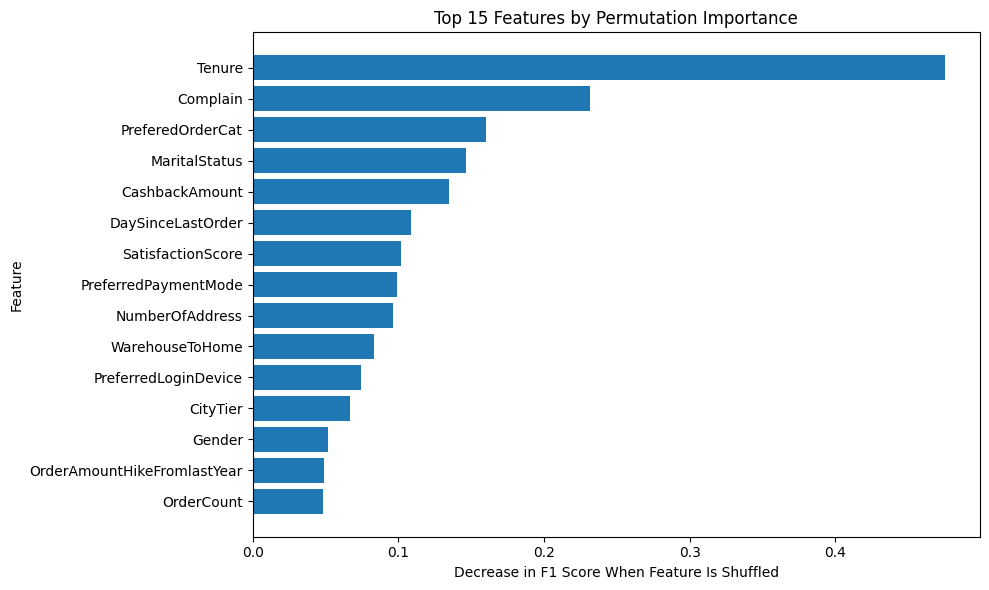

,Feature,Importance
0,Tenure,0.4756
12,Complain,0.2319
8,PreferedOrderCat,0.1604
10,MaritalStatus,0.1462
17,CashbackAmount,0.1346
16,DaySinceLastOrder,0.1087
9,SatisfactionScore,0.1018
4,PreferredPaymentMode,0.0991
11,NumberOfAddress,0.0963
3,WarehouseToHome,0.0835


In [10]:
# Feature Importance Using Permutation Importance

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean
}).sort_values("Importance", ascending=False)

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features by Permutation Importance")
plt.xlabel("Decrease in F1 Score When Feature Is Shuffled")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

display(importance_df.head(15).round(4))

##### Feature Importance Analysis

_I used __Permutation Importance__ to identify which features have the greatest impact on the Random Forest model's predictions. The results show that __Tenure__ is the most important feature, followed by __Complain, PreferredOrderCat, MaritalStatus, and CashbackAmount__. These features have the largest impact on the model's F1 Score when their values are shuffled, suggesting they are important for predicting customer churn._

---


### Conclusion

In this project, I analyzed an e-commerce dataset containing __5,630 customers__ to predict customer churn using machine learning. I explored the data, handled missing values, encoded categorical features, and divided the dataset into training (80%) and testing (20%) sets.

I trained and compared three models: __Logistic Regression, Decision Tree, and Random Forest__. Random Forest achieved the best overall performance, with __97.4% accuracy, 99.4% precision, 85.3% recall, and a 91.8% F1 Score__.

The feature importance analysis showed that __Tenure, Complain, PreferredOrderCat, MaritalStatus, and CashbackAmount__ were the most influential features in the model.

Overall, the project demonstrates how machine learning can help businesses identify customers at risk of leaving and better understand the factors associated with customer churn. However, the model should be tested on new customer data before being used in a real business environment.

---